In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")

print("Clean data:", Clean_Data_Path)
print("Output tables:", Table_Path)
print("Output charts:", Chart_Path)

Clean data: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data
Output tables: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts


In [3]:
orders = pd.read_csv(
    Clean_Data_Path / "orders_clean.csv"
)

order_items = pd.read_csv(
    Clean_Data_Path / "order_items_clean.csv"
)

customers = pd.read_csv(
    Clean_Data_Path / "customers_clean.csv"
)

sellers = pd.read_csv(
    Clean_Data_Path / "sellers_clean.csv"
)

reviews = pd.read_csv(
    Clean_Data_Path / "reviews_clean.csv"
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)
print("Reviews:", reviews.shape)

Orders: (96461, 8)
Order items: (112650, 7)
Customers: (99441, 5)
Sellers: (3095, 4)
Reviews: (99224, 7)


In [4]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

In [5]:
#order-level financial data
order_financials = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        order_revenue=("price", "sum"),
        order_freight=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
)

order_financials["order_total_value"] = (
    order_financials["order_revenue"]
    + order_financials["order_freight"]
)

order_financials.head()

,order_id,order_revenue,order_freight,item_count,order_total_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04


In [6]:
#operations base table
operations = orders.merge(
    order_financials,
    on="order_id",
    how="left"
)

operations = operations.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_state",
            "customer_city"
        ]
    ],
    on="customer_id",
    how="left"
)

print(operations.shape)
operations.head()

(96461, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_revenue,order_freight,item_count,order_total_value,customer_unique_id,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,29.99,8.72,1,38.71,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,118.70,22.76,1,141.46,af07308b275d755c9edb36a90c618231,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,159.90,19.22,1,179.12,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,45.00,27.20,1,72.20,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,19.90,8.72,1,28.62,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre


In [7]:
#Delivery metrics
operations["delivery_days"] = (
    operations["order_delivered_customer_date"]
    - operations["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

operations["estimated_delivery_days"] = (
    operations["order_estimated_delivery_date"]
    - operations["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

operations["delivery_difference_days"] = (
    operations["order_delivered_customer_date"].dt.normalize()
    - operations["order_estimated_delivery_date"].dt.normalize()
).dt.days

In [8]:
#SLA status
def classify_sla(row):
    if row["order_status"] != "delivered":
        return "Not Delivered"

    actual = row["order_delivered_customer_date"]
    estimated = row["order_estimated_delivery_date"]

    if pd.isna(actual) or pd.isna(estimated):
        return "Not Available"
    if actual.normalize() < estimated.normalize():
        return "Early"
    if actual.normalize() == estimated.normalize():
        return "On Time"
    return "Delayed"


operations["sla_status"] = operations.apply(
    classify_sla,
    axis=1
)

operations["sla_status"].value_counts()

sla_status
Early            88630
Delayed           6533
On Time           1292
Not Delivered        6
Name: count, dtype: int64

In [9]:
#Delivery-time bands
operations["delivery_time_band"] = pd.cut(
    operations["delivery_days"],
    bins=[-np.inf, 3, 7, 14, 30, np.inf],
    labels=[
        "0-3 days",
        "4-7 days",
        "8-14 days",
        "15-30 days",
        "30+ days"
    ]
)

operations["delivery_time_band"].value_counts(
    sort=False
)

delivery_time_band
0-3 days       4753
4-7 days      21293
8-14 days     40204
15-30 days    25659
30+ days       4552
Name: count, dtype: int64

In [10]:
#Overall operations KPI
delivered_operations = operations[
    (operations["order_status"] == "delivered")
    & operations["order_delivered_customer_date"].notna()
].copy()

operations_kpis = pd.DataFrame({
    "metric": [
        "Delivered Orders",
        "Average Delivery Days",
        "Average Estimated Delivery Days",
        "Delay Rate",
        "Average Freight",
        "Average Order Revenue",
        "Average Order Total Value"
    ],
    "value": [
        len(delivered_operations),

        round(
            delivered_operations["delivery_days"].mean(),
            2
        ),

        round(
            delivered_operations["estimated_delivery_days"].mean(),
            2
        ),

        round(
            (
                delivered_operations["sla_status"]
                .eq("Delayed")
                .mean()
                * 100
            ),
            2
        ),

        round(
            operations["order_freight"].mean(),
            2
        ),

        round(
            operations["order_revenue"].mean(),
            2
        ),

        round(
            operations["order_total_value"].mean(),
            2
        )
    ]
})

operations_kpis

,metric,value
0,Delivered Orders,96455.00
1,Average Delivery Days,12.56
2,Average Estimated Delivery Days,23.73
3,Delay Rate,6.77
4,Average Freight,22.79
5,Average Order Revenue,137.04
6,Average Order Total Value,159.83


In [11]:
operations_kpis.to_csv(
    Table_Path / "operations_kpis.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "operations_kpis.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\operations_kpis.csv


In [12]:
#SLA distribution
sla_summary = (
    operations[
        operations["sla_status"] != "Not Available"
    ]
    .groupby("sla_status")
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_freight=("order_freight", "mean")
    )
    .reset_index()
)

sla_summary["percentage"] = (
    sla_summary["orders"]
    / sla_summary["orders"].sum()
    * 100
)

sla_summary

,sla_status,orders,average_delivery_days,average_freight,percentage
0,Delayed,6533,33.947458,25.249167,6.772685
1,Early,88630,10.883875,22.623912,91.881693
2,Not Delivered,6,20.360006,17.066667,0.006220
3,On Time,1292,19.222630,21.468003,1.339401


In [13]:
sla_summary.to_csv(
    Table_Path / "sla_performance_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "sla_performance_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\sla_performance_summary.csv


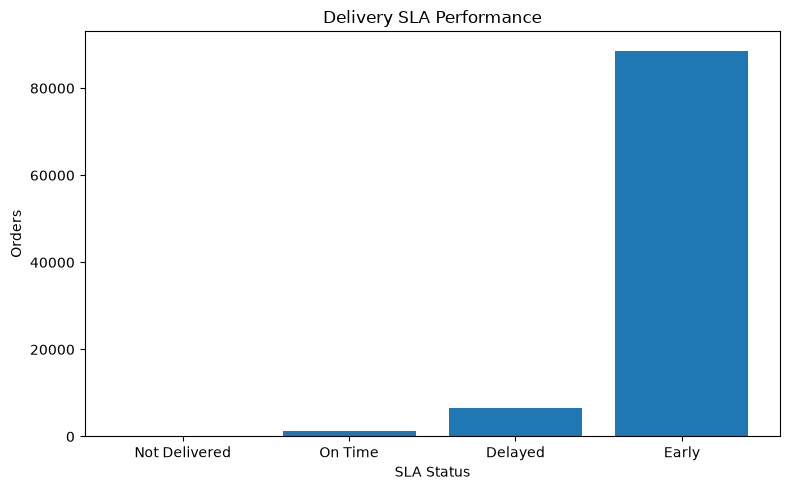

In [14]:
#SLA chart
sla_chart = (
    sla_summary
    .sort_values("orders")
)

plt.figure(figsize=(8, 5))

plt.bar(
    sla_chart["sla_status"],
    sla_chart["orders"]
)

plt.title("Delivery SLA Performance")
plt.xlabel("SLA Status")
plt.ylabel("Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path / "21_delivery_sla_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
#Delivery-time distribution
delivery_distribution = (
    delivered_operations
    .groupby(
        "delivery_time_band",
        observed=True
    )
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

delivery_distribution

,delivery_time_band,orders,average_delivery_days
0,0-3 days,4753,2.196317
1,4-7 days,21293,5.212998
2,8-14 days,40201,10.086720
3,15-30 days,25659,19.287470
4,30+ days,4549,41.639780


In [16]:
#Save delivery distribution
delivery_distribution.to_csv(
    Table_Path / "delivery_time_distribution.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "delivery_time_distribution.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\delivery_time_distribution.csv


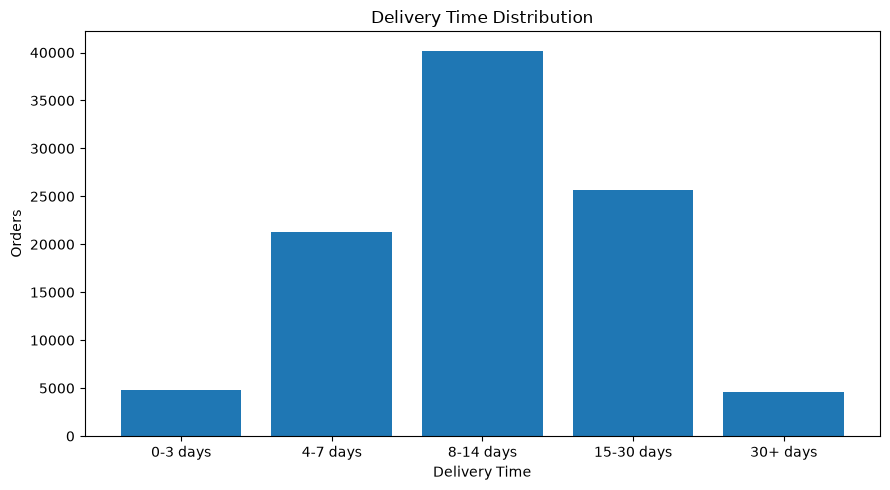

In [17]:
#Delivery distribution chart
plt.figure(figsize=(9, 5))

plt.bar(
    delivery_distribution["delivery_time_band"].astype(str),
    delivery_distribution["orders"]
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time")
plt.ylabel("Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path / "22_delivery_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
#Operations by customer state
state_operations = (
    delivered_operations
    .groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_freight=("order_freight", "mean"),
        delayed_orders=(
            "sla_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

state_operations["delay_rate_percent"] = (
    state_operations["delayed_orders"]
    / state_operations["delivered_orders"]
    * 100
)

state_operations = state_operations.sort_values(
    "delay_rate_percent",
    ascending=False
)

state_operations.head(10)

,customer_state,delivered_orders,average_delivery_days,average_freight,delayed_orders,delay_rate_percent
1,AL,397,24.543855,38.581285,85,21.410579
9,MA,716,21.584864,42.971159,125,17.458101
24,SE,335,21.519788,40.940119,51,15.223881
16,PI,476,19.457098,42.977290,66,13.865546
5,CE,1278,21.268656,36.504358,176,13.771518
21,RR,41,29.387546,48.342683,5,12.195122
4,BA,3256,19.335466,29.961201,396,12.162162
18,RJ,12348,15.309935,23.947654,1495,12.107224
13,PA,946,23.772917,39.696596,106,11.205074
7,ES,1995,15.789307,24.568662,214,10.726817


In [19]:
#Filter very small states
state_operations_reliable = (
    state_operations[
        state_operations["delivered_orders"] >= 100
    ]
    .copy()
)

state_operations_reliable.head(10)

,customer_state,delivered_orders,average_delivery_days,average_freight,delayed_orders,delay_rate_percent
1,AL,397,24.543855,38.581285,85,21.410579
9,MA,716,21.584864,42.971159,125,17.458101
24,SE,335,21.519788,40.940119,51,15.223881
16,PI,476,19.457098,42.977290,66,13.865546
5,CE,1278,21.268656,36.504358,176,13.771518
4,BA,3256,19.335466,29.961201,396,12.162162
18,RJ,12348,15.309935,23.947654,1495,12.107224
13,PA,946,23.772917,39.696596,106,11.205074
7,ES,1995,15.789307,24.568662,214,10.726817
14,PB,517,20.426768,48.842805,54,10.444874


In [20]:
state_operations_reliable.to_csv(
    Table_Path / "state_operations_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "state_operations_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\state_operations_summary.csv


In [21]:
#Seller operational performance
seller_operations = (
    order_items
    .groupby("seller_id")
    .agg(
        orders=("order_id", "nunique"),
        units_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        freight=("freight_value", "sum")
    )
    .reset_index()
)

In [22]:
#delivery information to seller orders
seller_order_delivery = order_items[
    [
        "order_id",
        "seller_id"
    ]
].drop_duplicates()

seller_order_delivery = seller_order_delivery.merge(
    operations[
        [
            "order_id",
            "delivery_days",
            "sla_status"
        ]
    ],
    on="order_id",
    how="left"
)

seller_delivery_summary = (
    seller_order_delivery
    .groupby("seller_id")
    .agg(
        delivery_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        delayed_orders=(
            "sla_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

seller_delivery_summary["delay_rate_percent"] = (
    seller_delivery_summary["delayed_orders"]
    / seller_delivery_summary["delivery_orders"]
    * 100
)

In [23]:
#Combine seller performance
seller_operations = seller_operations.merge(
    seller_delivery_summary,
    on="seller_id",
    how="left"
)

seller_operations = seller_operations.merge(
    sellers[
        [
            "seller_id",
            "seller_city",
            "seller_state"
        ]
    ],
    on="seller_id",
    how="left"
)

seller_operations.head()

,seller_id,orders,units_sold,revenue,freight,delivery_orders,average_delivery_days,delayed_orders,delay_rate_percent,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,3,3,2685.00,63.06,3,10.793885,0,0.000000,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,200,239,25080.03,8854.14,200,13.405805,12,6.000000,cariacica,ES
2,001e6ad469a905060d959994f1b41e4f,1,1,250.00,17.94,1,NaN,0,0.000000,sao goncalo,RJ
3,002100f778ceb8431b7a1020ff7ab48f,51,55,1234.50,793.66,51,16.386809,9,17.647059,franca,SP
4,003554e2dce176b5555353e4f3555ac8,1,1,120.00,19.38,1,4.646806,0,0.000000,goiania,GO


In [24]:
#Reliable seller operational view
seller_operations_reliable = (
    seller_operations[
        seller_operations["delivery_orders"] >= 20
    ]
    .sort_values(
        "delay_rate_percent",
        ascending=False
    )
)

seller_operations_reliable.head(20)

,seller_id,orders,units_sold,revenue,freight,delivery_orders,average_delivery_days,delayed_orders,delay_rate_percent,seller_city,seller_state
2877,ede0c03645598cdfc63ca8237acbe73d,46,50,2518.37,751.50,46,18.589665,14,30.434783,ribeirao preto,SP
1566,7f152321c60a266edc53af1925ef96c1,20,20,3919.80,552.12,20,23.469773,6,30.000000,criciuma,SC
2990,f76a3b1349b6df1ee875d1f3fa4340f0,24,24,4160.79,588.19,24,17.022680,7,29.166667,sao paulo,SP
1601,821fb029fc6e495ca4f08a35d51e53a5,28,29,19187.42,1552.83,28,16.792826,8,28.571429,sao paulo,SP
59,054694fa03fe82cec4b7551487331d74,21,22,9983.10,720.65,21,30.793123,6,28.571429,itajobi,SP
1032,54965bbe3e4f07ae045b90b0b8541f52,78,86,10961.30,2203.54,78,26.165561,22,28.205128,foz do iguacu,PR
2092,ad781527c93d00d89a11eecd9dcad7c1,44,44,6899.57,2379.69,44,25.504659,12,27.272727,sao jose do rio preto,SP
2132,b19f3ca2ea475913750f25a5c37c8d8f,24,24,6202.91,1346.64,24,18.389999,6,25.000000,divinopolis,MG
492,2a1348e9addc1af5aaa619b1a3679d6b,52,55,2843.00,788.40,52,27.313097,13,25.000000,belo horizonte,MG
1614,835f0f7810c76831d6c7d24c7a646d4d,44,50,5130.00,964.03,44,18.097381,11,25.000000,sao paulo,SP


In [25]:
seller_operations_reliable.to_csv(
    Table_Path / "seller_operations_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "seller_operations_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\seller_operations_summary.csv


In [26]:
#Review + delivery relationship
review_summary = (
    reviews
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean")
    )
)

operations_reviews = delivered_operations[
    [
        "order_id",
        "delivery_days",
        "sla_status"
    ]
].merge(
    review_summary,
    on="order_id",
    how="left"
)

operations_reviews.head()

,order_id,delivery_days,sla_status,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,Early,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,Early,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,Early,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,Early,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,Early,5.0


In [27]:
#Review score by SLA
review_by_sla = (
    operations_reviews
    .dropna(subset=["review_score"])
    .groupby("sla_status")
    .agg(
        orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean"),
        average_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

review_by_sla

,sla_status,orders,average_review_score,average_delivery_days
0,Delayed,6380,2.271395,33.820638
1,Early,88149,4.294282,10.877345
2,On Time,1280,4.035547,19.191255


In [28]:
review_by_sla.to_csv(
    Table_Path / "review_by_delivery_status.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "review_by_delivery_status.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\review_by_delivery_status.csv


In [29]:
#Freight burden
operations["freight_to_revenue_percent"] = np.where(
    operations["order_revenue"] > 0,
    operations["order_freight"]
    / operations["order_revenue"]
    * 100,
    np.nan
)

freight_summary = (
    operations[
        operations["order_revenue"] > 0
    ]
    .groupby(
        pd.cut(
            operations["order_revenue"],
            bins=[0, 50, 100, 200, 500, np.inf],
            labels=[
                "0-50",
                "51-100",
                "101-200",
                "201-500",
                "500+"
            ]
        ),
        observed=True
    )
    .agg(
        orders=("order_id", "nunique"),
        average_freight=("order_freight", "mean"),
        average_freight_ratio=(
            "freight_to_revenue_percent",
            "mean"
        )
    )
    .reset_index()
)

freight_summary

,order_revenue,orders,average_freight,average_freight_ratio
0,0-50,29042,15.417084,56.787019
1,51-100,27602,19.173748,26.030051
2,101-200,25281,24.962880,17.756972
3,201-500,11059,35.213956,12.144802
4,500+,3477,57.651622,6.875776


In [30]:
freight_summary.to_csv(
    Table_Path / "freight_burden_analysis.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "freight_burden_analysis.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\freight_burden_analysis.csv


In [ ]:
operations_output = operations[
    [
        "order_id",
        "customer_id",
        "customer_unique_id",
        "customer_state",
        "customer_city",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "order_revenue",
        "order_freight",
        "order_total_value",
        "item_count",
        "delivery_days",
        "estimated_delivery_days",
        "delivery_difference_days",
        "sla_status",
        "delivery_time_band",
        "freight_to_revenue_percent"
    ]
].copy()

operations_output.to_csv(
    Table_Path / "operations_order_level.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "operations_order_level.csv"
)

In [32]:
print("Operations rows:", len(operations_output))

print("\nSLA distribution:")
print(
    operations_output["sla_status"]
    .value_counts(dropna=False)
)

print("\nMissing delivery days:")
print(
    operations_output["delivery_days"]
    .isna()
    .sum()
)

print("\nOperations KPI:")
print(operations_kpis)

Operations rows: 96461

SLA distribution:
sla_status
Early      88635
Delayed     6534
On Time     1292
Name: count, dtype: int64

Missing delivery days:
0

Operations KPI:
                            metric     value
0                 Delivered Orders  96461.00
1            Average Delivery Days     12.56
2  Average Estimated Delivery Days     23.74
3                       Delay Rate      6.77
4                  Average Freight     22.79
5            Average Order Revenue    137.04
6        Average Order Total Value    159.83
